# Modellentwicklung: $SpO_2$-Vorhersage (Lösung)

In diesem Notebook trainieren wir ein Modell mit den Daten, die wir in der letzten Sitzung aufbereitet haben. Ziel ist es, mit dem trainierten Modell **$SpO_2$-Werte vorherzusagen** und die Ergebnisse des Modells zu **bewerten**.

### Die Fragestellung
Können wir aus den letzten 5 $SpO_2$-Messungen einer Patientin / eines Patienten den **nächsten** Messwert vorhersagen? So etwas ist die Grundidee hinter Frühwarnsystemen auf der Intensivstation: Eine drohende Entsättigung soll erkannt werden, *bevor* sie eintritt.

### Das Vorgehen
1. Aus den Zeitreihen jedes Aufenthalts schneiden wir **Fenster** aus 5 aufeinanderfolgenden Werten (Eingabe) plus dem 6. Wert (Zielwert).
2. Damit trainieren wir einen **Random Forest Regressor**. *Regressor*, weil wir eine Zahl vorhersagen (nicht eine Kategorie wie in Tutorial 04).
3. Wir bewerten das Modell mit MAE, RMSE und $R^2$ und stellen Vorhersagen und Fehler grafisch dar.

### Aufbau dieser Lösung
- **Teil 1** löst die Aufgaben aus der Übung.
- **Teil 2** geht darüber hinaus und stellt die Frage, die man bei jedem Modell stellen muss: *Ist das Ergebnis eigentlich gut – und klinisch brauchbar?*
- **Teil 3** evaluiert das finale Modell systematisch (Kreuzvalidierung, Bland-Altman, Ergebnisse pro Person) und interpretiert, was es gelernt hat.

---
# Teil 1: Die Übungsaufgaben

## Warum ein Random Forest für diese Aufgabe?

**1. Aus einer Zeitreihe wird eine Tabelle.** Durch das „Schiebefenster“ wird jede Vorhersage zu einer Tabellenzeile mit 5 Spalten (die letzten 5 Werte) und einem Zielwert. Damit lässt sich ein ganz normales Modell für tabellarische Daten verwenden, ohne spezielle Zeitreihenverfahren.

**2. Der Random Forest passt gut zu solchen Tabellen.**
- Er erkennt **nichtlineare Zusammenhänge und Muster** wie „fällt seit drei Messungen“ oder „ein einzelner Ausreißer nach unten“, ohne dass wir solche Merkmale selbst konstruieren müssen.
- Er braucht **keine Standardisierung** der Daten und funktioniert mit den Standardeinstellungen meist ordentlich.
- Viele Bäume werden gemittelt (*Bagging*). Das macht ihn deutlich **robuster** als einen einzelnen Entscheidungsbaum.
- Er sagt immer einen **Mittelwert aus Trainingswerten** vorher. Deshalb kann er nie physiologisch unmögliche Werte wie 103 % ausgeben, eine lineare Regression dagegen schon.
- Er ist bei rund 13.000 Zeilen in Sekunden trainiert. Neuronale Netze für Zeitreihen (z. B. LSTMs) bräuchten deutlich mehr Daten.
- Über die **Feature Importance** sehen wir, welche Messzeitpunkte das Modell am meisten nutzt.

**3. Aber:** Ob ein Modell „Sinn macht“, entscheidet nicht die Methode, sondern der Vergleich mit einfachen Alternativen. Genau das untersuchen wir in Teil 2. Die Antwort wird überraschen.

## Pakete importieren

Installieren Sie gegebenenfalls Pakete, die in Ihrer Python-Umgebung noch fehlen.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

# Zusätzlich für Teil 2
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold, cross_val_score

## Aufbereitete Daten laden

Geben Sie den Ordner an, in dem die Datei `05-5_final_spO2.csv` aus der letzten Sitzung liegt. Liegt sie im selben Ordner wie dieses Notebook, können Sie `"."` stehen lassen.

In [2]:
daten_ordner = "."    # z. B. r"C:\Users\name\Klinische_Informatik" unter Windows

Da wir eine CSV-Datei erstellt haben, laden wir sie mit `pd.read_csv` in einen DataFrame. Beim Speichern als CSV geht der Datentyp der Zeitspalte verloren, deshalb wandeln wir `time` direkt wieder in einen Zeitstempel um.

In [3]:
file_path = os.path.join(daten_ordner, "05-5_final_spO2.csv")
data = pd.read_csv(file_path, index_col="index")
data["time"] = pd.to_datetime(data["time"])
data.head()

,subject_id,stay_id,time,spo2
index,,,,
0,10000032,39553978,2180-07-23 14:13:00,98.0
1,10000032,39553978,2180-07-23 14:30:00,97.0
2,10000032,39553978,2180-07-23 15:00:00,97.0
3,10000032,39553978,2180-07-23 16:00:00,94.0
4,10000032,39553978,2180-07-23 17:00:00,95.0


## Aufgabe 1: Sequenzen und Zielwerte erzeugen

Erzeugen Sie den Eingabedatensatz und die zugehörigen Zielwerte, indem Sie die Funktion `create_sequences` vervollständigen. Die Beschreibung im Docstring erklärt, was die Funktion tun soll.

*Tipps:*
- `data["stay_id"].unique()` liefert jede stay_id genau einmal.
- Filtern und Sortieren: `data[data["stay_id"] == ...].sort_values("time")` (Tutorial 02)
- Ein Ausschnitt einer Liste: `werte[i : i + 5]` (Tutorial 01, Abschnitt 7)
- Sammeln Sie Sequenzen, Zielwerte und stay_ids zunächst in drei normalen Listen und wandeln Sie sie am Ende um: `pd.DataFrame(...)` bzw. `np.array(...)`.

In [4]:
def create_sequences(data, sequence_length=5):
    """
    Erzeugt Sequenzen und zugehörige Zielwerte nach folgendem Schema:
        - Iterieren Sie über die stay_ids. Wichtig: Jede stay_id genau einmal durchlaufen,
          nicht jede Zeile des DataFrames! Extrahieren Sie die Daten eines Aufenthalts
          und sortieren Sie sie nach der Zeit.
        - Holen Sie sich die SpO2-Werte dieses Aufenthalts als Liste (= eine Zeitreihe).
        - Erzeugen Sie daraus Sequenzen und Zielwerte: Jeweils 5 aufeinanderfolgende Werte
          bilden eine Sequenz und dienen dazu, den darauffolgenden Wert (den 6.) vorherzusagen.
          Beispiel:
            originale_daten = [1, 2, 3, 4, 5, 6, 7, 8, 9]
            sequences = [[1, 2, 3, 4, 5], [2, 3, 4, 5, 6], [3, 4, 5, 6, 7], ...]
            targets   = [6, 7, 8, ...]
        - Merken Sie sich zu jeder Sequenz die zugehörige stay_id.

    Args:
        data: DataFrame mit den Spalten stay_id, time und spo2
        sequence_length: Länge einer Sequenz (Standard: 5)

    Returns:
        sequences -> pd.DataFrame (eine Zeile pro Sequenz, eine Spalte pro Zeitpunkt)
        targets   -> np.array
        stay_ids  -> np.array
    """
    sequences, targets, stay_ids = [], [], []

    for stay_id in data["stay_id"].unique():                       # jeder Aufenthalt genau einmal
        aufenthalt = data[data["stay_id"] == stay_id].sort_values("time")
        werte = aufenthalt["spo2"].tolist()                          # Zeitreihe dieses Aufenthalts

        for i in range(len(werte) - sequence_length):                # Fenster über die Zeitreihe schieben
            sequences.append(werte[i : i + sequence_length])
            targets.append(werte[i + sequence_length])
            stay_ids.append(stay_id)

    spalten = [f"t-{sequence_length - j}" for j in range(sequence_length)]   # t-5, t-4, ..., t-1
    return pd.DataFrame(sequences, columns=spalten), np.array(targets), np.array(stay_ids)

**Kurzer Funktionstest** mit dem Beispiel aus dem Docstring. Es lohnt sich immer, eine Funktion erst an einem winzigen Beispiel zu prüfen, bei dem man das Ergebnis im Kopf kennt:

In [5]:
test_daten = pd.DataFrame({
    "stay_id": [1] * 9,
    "time": pd.date_range("2180-01-01", periods=9, freq="h"),
    "spo2": [1, 2, 3, 4, 5, 6, 7, 8, 9],
})
test_seq, test_ziel, test_ids = create_sequences(test_daten)
print(test_seq)
print("Zielwerte:", test_ziel)

   t-5  t-4  t-3  t-2  t-1
0    1    2    3    4    5
1    2    3    4    5    6
2    3    4    5    6    7
3    4    5    6    7    8
Zielwerte: [6 7 8 9]


Aus 9 Werten entstehen 4 Sequenzen. Allgemein liefert eine Zeitreihe der Länge *n* genau *n − 5* Sequenzen. Aufenthalte mit 5 oder weniger Messungen tragen also gar nichts bei.

## Aufgabe 2: Funktion aufrufen

Rufen Sie die Funktion auf, um Sequenzen, Zielwerte und stay_ids zu erhalten, und geben Sie sie aus. Wie viele Sequenzen sind entstanden?

In [6]:
sequences, targets, stay_ids = create_sequences(data, sequence_length=5)

print("Anzahl Sequenzen:", len(sequences))
print("Zielwerte:", targets[:10], "...")
print("stay_ids: ", stay_ids[:10], "...")
sequences.head()

Anzahl Sequenzen: 12847
Zielwerte: [95. 98. 99. 95. 95. 94. 93. 98. 98. 98.] ...
stay_ids:  [39553978 39553978 39553978 39553978 39553978 37067082 37067082 37067082
 37067082 37067082] ...


,t-5,t-4,t-3,t-2,t-1
0,98.0,97.0,97.0,94.0,95.0
1,97.0,97.0,94.0,95.0,95.0
2,97.0,94.0,95.0,95.0,98.0
3,94.0,95.0,95.0,98.0,99.0
4,95.0,95.0,98.0,99.0,95.0


## Aufgabe 3: Modell definieren

Definieren Sie Ihr Modell, einen [`RandomForestRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html). Setzen Sie `random_state` auf 42, damit Ihre Ergebnisse reproduzierbar sind.

In [7]:
model = RandomForestRegressor(random_state=42)
model

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

Mit den Standardeinstellungen besteht der Wald aus 100 Bäumen (`n_estimators=100`), und jeder Baum wächst so lange, bis jedes Blatt nur noch einen Trainingsfall enthält. Diesen zweiten Punkt schauen wir uns in Teil 2 noch genauer an.

## Aufgabe 4: Trainieren, Vorhersagen, Bewerten

1. Teilen Sie Sequenzen und Zielwerte im Verhältnis **80:20** in Trainings- und Testdaten auf. Verwenden Sie einen `random_state`, damit die Aufteilung reproduzierbar ist. (Tutorial 04, Abschnitt 3)
2. Trainieren Sie das Modell mit den Trainingsdaten und sagen Sie die Zielwerte der Testdaten vorher. Die nötigen Funktionen finden Sie in der Dokumentation oben.
3. Berechnen Sie folgende Gütemaße:
   - **MAE** – mittlerer absoluter Fehler ([Dokumentation](https://scikit-learn.org/stable/modules/model_evaluation.html#mean-absolute-error))
   - **RMSE** – Wurzel aus dem mittleren quadratischen Fehler ([Dokumentation](https://scikit-learn.org/stable/modules/model_evaluation.html#mean-squared-error)). *Tipp:* `np.sqrt(mean_squared_error(...))`
   - **$R^2$** – Bestimmtheitsmaß ([Dokumentation](https://scikit-learn.org/stable/modules/model_evaluation.html#r2-score-the-coefficient-of-determination))

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    sequences, targets, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2   = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.2f} Prozentpunkte")
print(f"RMSE: {rmse:.2f} Prozentpunkte")
print(f"$R^2$:   {r2:.3f}")

MAE:  1.47 Prozentpunkte
RMSE: 2.42 Prozentpunkte
$R^2$:   0.276


### Was bedeuten die Gütemaße?

| Maß | Bedeutung | Einheit |
|---|---|---|
| **MAE** | Im Mittel liegt die Vorhersage um so viel daneben. | Prozentpunkte $SpO_2$ |
| **RMSE** | Wie MAE, aber große Fehler zählen überproportional (sie werden vor dem Mitteln quadriert). | Prozentpunkte $SpO_2$ |
| **$R^2$** | Anteil der Streuung der Zielwerte, den das Modell erklärt. 1 = perfekt, 0 = nicht besser, als immer den Mittelwert vorherzusagen. | ohne Einheit |

Ein MAE von etwa 1,5 Prozentpunkten klingt erst einmal sehr gut. Zur Einordnung: Pulsoxymeter haben selbst eine Messungenauigkeit von etwa ±2 Prozentpunkten. Das $R^2$ zeigt aber, dass das Modell nur einen kleinen Teil der Schwankungen erklärt.

Ist RMSE deutlich größer als MAE, gibt es **einige große Fehler**. Darauf kommen wir beim Fehler-Plot zurück.

**Schauen wir zum Vergleich auf die Trainingsdaten:**

In [9]:
y_pred_train = model.predict(X_train)
print(f"$R^2$ Training: {r2_score(y_train, y_pred_train):.3f}")
print(f"$R^2$ Test:     {r2:.3f}")

$R^2$ Training: 0.808
$R^2$ Test:     0.276


Auf den Trainingsdaten ist das Modell deutlich besser als auf den Testdaten. Das ist ein klassisches Zeichen für **Overfitting**: Die voll ausgewachsenen Bäume haben die Trainingsdaten teilweise auswendig gelernt, einschließlich des Messrauschens.

## Aufgabe 5: Vorhersagen gegen wahre Werte darstellen

Stellen Sie Ihre Vorhersagen den wahren Zielwerten in einer Grafik gegenüber.

*Tipp:* Ein Streudiagramm mit den wahren Werten auf der x-Achse und den Vorhersagen auf der y-Achse. Eine Diagonale (`ax.plot([min, max], [min, max])`) zeigt, wo perfekte Vorhersagen liegen würden. (Tutorial 03, Abschnitt 6)

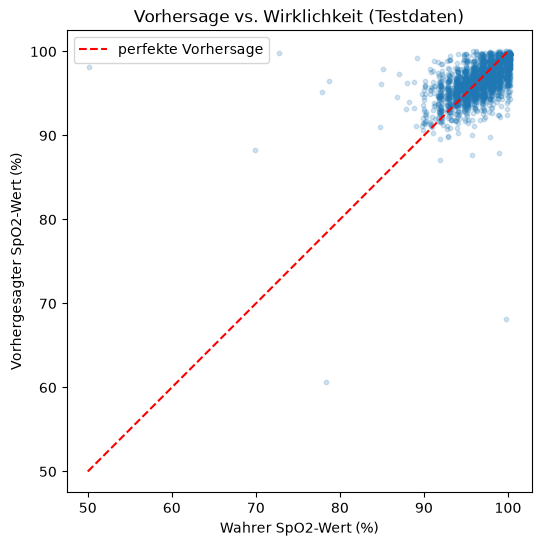

In [10]:
rng = np.random.default_rng(0)
jitter = rng.uniform(-0.3, 0.3, size=len(y_test))   # SpO2 ist ganzzahlig -> leicht verwackeln

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test + jitter, y_pred, alpha=0.2, s=10)
untergrenze = min(y_test.min(), y_pred.min())
ax.plot([untergrenze, 100], [untergrenze, 100], color="red", linestyle="--", label="perfekte Vorhersage")
ax.set_xlabel("Wahrer SpO2-Wert (%)")
ax.set_ylabel("Vorhergesagter SpO2-Wert (%)")
ax.set_title("Vorhersage vs. Wirklichkeit (Testdaten)")
ax.legend()
plt.show()

Zwei Beobachtungen:
- Die meisten Punkte drängen sich zwischen 92 und 100 %. Dort liegen fast alle Messwerte.
- Bei niedrigen wahren Werten liegen die Vorhersagen fast immer **zu hoch** (oberhalb der Diagonale). Das Modell sieht plötzliche Entsättigungen nicht kommen. Es sagt eher „so wie bisher“ voraus.

Da die Werte ganzzahlig sind, liegen ohne den kleinen „Jitter“ alle Punkte in senkrechten Linien übereinander. Der Jitter verschiebt sie nur für die Darstellung minimal nach links oder rechts.

## Aufgabe 6: Fehler darstellen

Stellen Sie die Fehler Ihres Modells grafisch dar.

*Tipp:* Berechnen Sie den Fehler als `y_pred - y_test` und zeichnen Sie z. B. ein Histogramm. Überlegen Sie auch: Sind die Fehler bei allen $SpO_2$-Werten gleich groß?

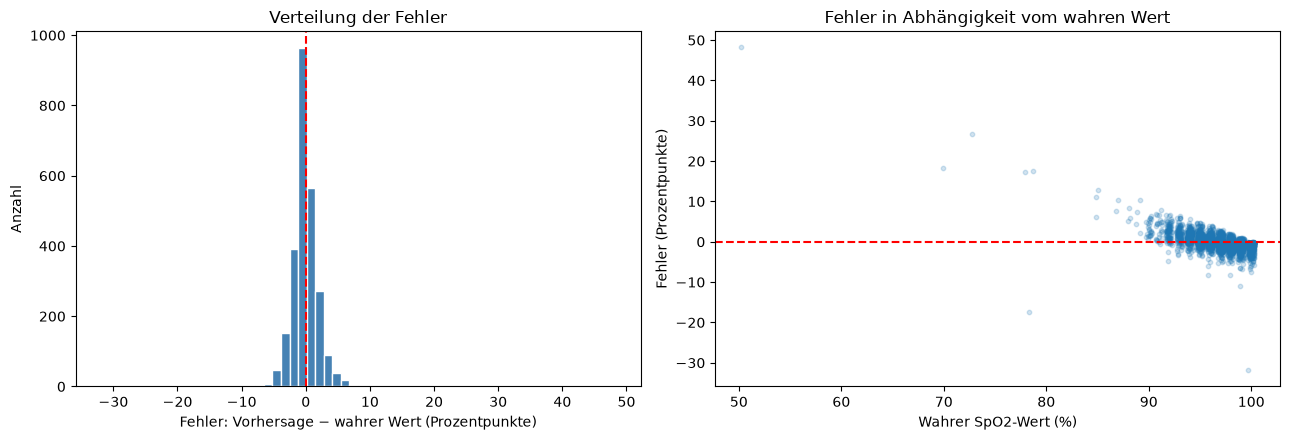

In [11]:
fehler = y_pred - y_test

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.hist(fehler, bins=60, color="steelblue", edgecolor="white")
ax1.axvline(0, color="red", linestyle="--")
ax1.set_xlabel("Fehler: Vorhersage − wahrer Wert (Prozentpunkte)")
ax1.set_ylabel("Anzahl")
ax1.set_title("Verteilung der Fehler")

ax2.scatter(y_test + jitter, fehler, alpha=0.2, s=10)
ax2.axhline(0, color="red", linestyle="--")
ax2.set_xlabel("Wahrer SpO2-Wert (%)")
ax2.set_ylabel("Fehler (Prozentpunkte)")
ax2.set_title("Fehler in Abhängigkeit vom wahren Wert")

fig.tight_layout()
plt.show()

- **Links:** Die meisten Fehler liegen nahe 0, aber die Verteilung ist **schief**. Nach rechts (Vorhersage zu hoch) gibt es einen langen Ausläufer. Daher kommt auch, dass RMSE größer ist als MAE.
- **Rechts:** Je niedriger der wahre Wert, desto größer der Fehler. Das Modell ist dort am schlechtesten, wo es **klinisch am wichtigsten** wäre.

---
# Teil 2: Vertiefung – Ist das Modell wirklich gut?

Wir haben ein Modell mit einem MAE von etwa 1,5 Prozentpunkten. Bevor man so etwas in einer Publikation oder gar in einem klinischen System verwendet, muss man vier Fragen stellen:

1. **Baseline:** Ist das Modell besser als eine ganz einfache Regel?
2. **Datenleck:** Wurde ehrlich getestet, also an *neuen* Patient\*innen?
3. **Einstellungen:** Lässt sich das Overfitting reduzieren?
4. **Klinischer Nutzen:** Erkennt das Modell die Situationen, auf die es ankommt?

## 2.1 Vergleich mit einfachen Baselines

Eine **Baseline** ist eine triviale Vorhersage ohne maschinelles Lernen. Ein Modell, das die Baseline nicht schlägt, ist überflüssig, egal wie gut seine Zahlen auf den ersten Blick aussehen. Wir vergleichen mit drei einfachen Regeln:
- **Letzter Wert:** Der nächste Wert ist gleich dem zuletzt gemessenen (`t-1`).
- **Mittelwert:** Der nächste Wert ist der Mittelwert der letzten 5 Werte.
- **Median:** Der nächste Wert ist der Median der letzten 5 Werte.

Da wir die Gütemaße jetzt öfter brauchen, schreiben wir eine kleine Hilfsfunktion:

In [12]:
def guetemasse(y_wahr, y_vorhersage):
    return {
        "MAE":  mean_absolute_error(y_wahr, y_vorhersage),
        "RMSE": np.sqrt(mean_squared_error(y_wahr, y_vorhersage)),
        "$R^2$":   r2_score(y_wahr, y_vorhersage),
    }

vergleich = pd.DataFrame({
    "Random Forest":       guetemasse(y_test, y_pred),
    "Baseline: letzter Wert": guetemasse(y_test, X_test["t-1"]),
    "Baseline: Mittelwert":   guetemasse(y_test, X_test.mean(axis=1)),
    "Baseline: Median":       guetemasse(y_test, X_test.median(axis=1)),
}).T
vergleich.round(3)

,MAE,RMSE,$R^2$
Random Forest,1.465,2.416,0.276
Baseline: letzter Wert,1.410,2.662,0.121
Baseline: Mittelwert,1.410,2.330,0.327
Baseline: Median,1.386,2.392,0.290


**Das ist das wichtigste Ergebnis dieses Notebooks:** Der Random Forest mit Standardeinstellungen ist **nicht besser** als die einfache Regel „Mittelwert der letzten 5 Werte“, eher sogar etwas schlechter. Ohne Baseline wäre uns das nie aufgefallen.

Warum ist das so? $SpO_2$ ist bei den meisten Patient\*innen über Stunden ziemlich stabil, und die Schwankungen von Messung zu Messung sind zum großen Teil **Messrauschen**. Rauschen ist nicht vorhersagbar. Die beste Strategie ist dann, das Rauschen herauszumitteln, und genau das macht der Mittelwert. Der Random Forest dagegen hat mit seinen voll ausgewachsenen Bäumen das Rauschen der Trainingsdaten mitgelernt (siehe Overfitting in Teil 1).

## 2.2 Datenleck: Aufteilung nach Patient\*innen

Bei `train_test_split` werden die **Sequenzen** zufällig verteilt. Sequenzen desselben Aufenthalts landen dann sowohl im Training als auch im Test. Und weil sich benachbarte Fenster überlappen (z. B. `[97, 98, 96, 97, 99]` und `[98, 96, 97, 99, 98]`), hat das Modell Teile der Testdaten praktisch schon gesehen.

In der Praxis soll das Modell aber bei **neuen Patient\*innen** funktionieren. Ehrlicher ist deshalb eine Aufteilung nach `subject_id`: Alle Daten einer Person sind entweder im Training oder im Test. Genau dafür hat unsere Funktion die `stay_ids` zurückgegeben. Da manche Personen mehrere Aufenthalte haben, ordnen wir jeder Sequenz zusätzlich die `subject_id` zu:

In [13]:
stay_zu_subject = data.drop_duplicates("stay_id").set_index("stay_id")["subject_id"]
subject_ids = stay_zu_subject.loc[stay_ids].values

print("Anzahl Patient*innen:", len(np.unique(subject_ids)))
print("Anzahl Aufenthalte:  ", len(np.unique(stay_ids)))

Anzahl Patient*innen: 100
Anzahl Aufenthalte:   137


Ein einzelner Split hängt stark davon ab, welche Patient\*innen zufällig im Test landen. Deshalb vergleichen wir mit **5-facher Kreuzvalidierung** (Tutorial 04, Abschnitt 10):
- `KFold`: zufällige Aufteilung der Sequenzen, wie oben
- `GroupKFold`: Aufteilung nach Patient\*innen

*(Diese Zelle rechnet etwa eine halbe Minute.)*

In [14]:
rf = RandomForestRegressor(random_state=42, n_jobs=-1)

mae_zufaellig = -cross_val_score(rf, sequences, targets,
                                 cv=KFold(5, shuffle=True, random_state=42),
                                 scoring="neg_mean_absolute_error")
mae_patienten = -cross_val_score(rf, sequences, targets,
                                 cv=GroupKFold(5), groups=subject_ids,
                                 scoring="neg_mean_absolute_error")

print(f"MAE zufällige Aufteilung:       {mae_zufaellig.mean():.3f}  (je Fold: {mae_zufaellig.round(2)})")
print(f"MAE Aufteilung nach Patient*in: {mae_patienten.mean():.3f}  (je Fold: {mae_patienten.round(2)})")

MAE zufällige Aufteilung:       1.498  (je Fold: [1.47 1.47 1.5  1.55 1.5 ])
MAE Aufteilung nach Patient*in: 1.508  (je Fold: [1.49 1.6  1.49 1.51 1.45])


In diesem Datensatz ist der Unterschied klein. Das liegt daran, dass die Zeitreihen so stark vom Rauschen geprägt sind, dass es kaum etwas Patientenspezifisches „auswendig zu lernen“ gibt. **Das ist aber kein Freibrief:** Bei Daten mit mehr individueller Struktur (z. B. Bilder, Laborverläufe) kann ein solches Datenleck die Ergebnisse massiv beschönigen. Die Aufteilung nach Patient\*innen ist der methodisch korrekte Weg und wird von Gutachter\*innen erwartet.

Achten Sie außerdem auf die **Streuung zwischen den Folds**: Je nachdem, welche Patient\*innen im Test landen, schwankt der MAE um rund 0,1 Prozentpunkte. Das ist mehr, als das Modell später gegenüber der Baseline gewinnt (Abschnitt 2.3). Bei nur 100 Patient\*innen ist jede einzelne Zahl mit Vorsicht zu genießen.

Ab jetzt verwenden wir für alle Vergleiche die Aufteilung nach Patient\*innen.

## 2.3 Overfitting reduzieren: der Parameter `min_samples_leaf`

Standardmäßig wachsen die Bäume, bis jedes Blatt nur noch **einen** Trainingsfall enthält. Bei verrauschten Daten lernt der Baum dann das Rauschen mit. Mit `min_samples_leaf` legen wir fest, wie viele Trainingsfälle ein Blatt mindestens enthalten muss. Jede Vorhersage ist dann ein Mittelwert über mindestens so viele ähnliche Fälle, und das Modell wird „glatter“.

*(Diese Zelle rechnet etwa eine Minute.)*

In [15]:
blattgroessen = [1, 5, 10, 20, 50, 100, 200]
ergebnisse = []

for blatt in blattgroessen:
    rf = RandomForestRegressor(min_samples_leaf=blatt, random_state=42, n_jobs=-1)
    mae = -cross_val_score(rf, sequences, targets, cv=GroupKFold(5), groups=subject_ids,
                           scoring="neg_mean_absolute_error")
    ergebnisse.append(mae.mean())
    print(f"min_samples_leaf = {blatt:>3}:  MAE = {mae.mean():.3f}")

# Baseline "Mittelwert der letzten 5 Werte" mit denselben Folds
mae_baseline = np.mean([
    mean_absolute_error(targets[test], sequences.iloc[test].mean(axis=1))
    for train, test in GroupKFold(5).split(sequences, targets, groups=subject_ids)
])

min_samples_leaf =   1:  MAE = 1.508
min_samples_leaf =   5:  MAE = 1.391
min_samples_leaf =  10:  MAE = 1.366
min_samples_leaf =  20:  MAE = 1.355
min_samples_leaf =  50:  MAE = 1.346
min_samples_leaf = 100:  MAE = 1.346
min_samples_leaf = 200:  MAE = 1.358


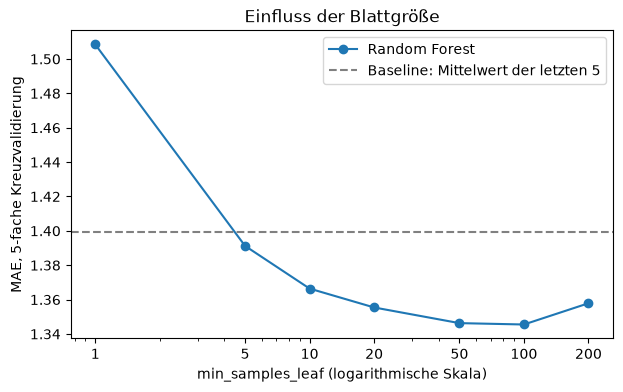

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(blattgroessen, ergebnisse, marker="o", label="Random Forest")
ax.axhline(mae_baseline, color="gray", linestyle="--", label="Baseline: Mittelwert der letzten 5")
ax.set_xscale("log")
ax.set_xticks(blattgroessen)
ax.set_xticklabels(blattgroessen)
ax.set_xlabel("min_samples_leaf (logarithmische Skala)")
ax.set_ylabel("MAE, 5-fache Kreuzvalidierung")
ax.set_title("Einfluss der Blattgröße")
ax.legend()
plt.show()

Mit größeren Blättern wird der Random Forest besser und schlägt ab einer gewissen Blattgröße die Baseline, allerdings nur **knapp**. Das passende Maß an „Glättung“ zu finden, nennt man **Hyperparameter-Tuning**.

> **Methodischer Hinweis:** Wir wählen die beste Blattgröße hier anhand der Kreuzvalidierung. Streng genommen bräuchte man danach noch einmal einen völlig unberührten Testdatensatz, um das ausgewählte Modell unverzerrt zu bewerten.

## 2.4 Wie lang sollte eine Sequenz sein?

Die Länge 5 war eine willkürliche Vorgabe. Wir testen andere Längen. Da `create_sequences` die Länge als Parameter hat, ist das nur eine Schleife.

> Beachten Sie: Bei längeren Sequenzen fallen mehr kurze Aufenthalte weg, die Datensätze sind also nicht ganz identisch. Der Vergleich ist daher nur ein Anhaltspunkt.

*(Diese Zelle rechnet etwa eine Minute.)*

In [17]:
laengen = [1, 2, 3, 5, 10, 20]

for laenge in laengen:
    seq_l, ziel_l, stays_l = create_sequences(data, sequence_length=laenge)
    subj_l = stay_zu_subject.loc[stays_l].values
    rf = RandomForestRegressor(min_samples_leaf=20, random_state=42, n_jobs=-1)
    mae = -cross_val_score(rf, seq_l, ziel_l, cv=GroupKFold(5), groups=subj_l,
                           scoring="neg_mean_absolute_error")
    print(f"Sequenzlänge {laenge:>2}:  {len(ziel_l):>5} Sequenzen,  MAE = {mae.mean():.3f}")

Sequenzlänge  1:  13400 Sequenzen,  MAE = 1.431
Sequenzlänge  2:  13260 Sequenzen,  MAE = 1.380
Sequenzlänge  3:  13122 Sequenzen,  MAE = 1.368
Sequenzlänge  5:  12847 Sequenzen,  MAE = 1.355
Sequenzlänge 10:  12165 Sequenzen,  MAE = 1.350
Sequenzlänge 20:  10852 Sequenzen,  MAE = 1.351


Ein paar Werte Vorgeschichte helfen, sehr lange Sequenzen bringen keinen Gewinn mehr. Die Messung von vor 20 Stunden sagt wenig über die nächste Stunde aus.

## 2.5 Das finale Modell: ehrlich bewertet

Wir trainieren jetzt ein Modell mit `min_samples_leaf=20` auf einer Aufteilung nach Patient\*innen (80:20) und vergleichen es mit der Baseline auf **denselben** Testpatient\*innen.

In [18]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(sequences, targets, groups=subject_ids))

X_tr, X_te = sequences.iloc[train_idx], sequences.iloc[test_idx]
y_tr, y_te = targets[train_idx], targets[test_idx]
stays_te = stay_ids[test_idx]

print("Test-Patient*innen:", len(np.unique(subject_ids[test_idx])),
      "| Test-Sequenzen:", len(y_te))

finales_modell = RandomForestRegressor(min_samples_leaf=20, random_state=42, n_jobs=-1)
finales_modell.fit(X_tr, y_tr)
y_pred_final = finales_modell.predict(X_te)
y_baseline = X_te.mean(axis=1).values

pd.DataFrame({
    "Random Forest (min_samples_leaf=20)": guetemasse(y_te, y_pred_final),
    "Random Forest (Standard)": guetemasse(
        y_te, RandomForestRegressor(random_state=42, n_jobs=-1).fit(X_tr, y_tr).predict(X_te)),
    "Baseline: Mittelwert": guetemasse(y_te, y_baseline),
    "Baseline: letzter Wert": guetemasse(y_te, X_te["t-1"]),
}).T.round(3)

Test-Patient*innen: 20 | Test-Sequenzen: 2738


,MAE,RMSE,$R^2$
Random Forest (min_samples_leaf=20),1.299,1.962,0.412
Random Forest (Standard),1.445,2.095,0.329
Baseline: Mittelwert,1.355,2.003,0.387
Baseline: letzter Wert,1.389,2.219,0.248


## 2.6 Welche Messzeitpunkte nutzt das Modell?

Die **Feature Importance** zeigt, wie stark jede Eingabespalte zu den Entscheidungen der Bäume beiträgt.

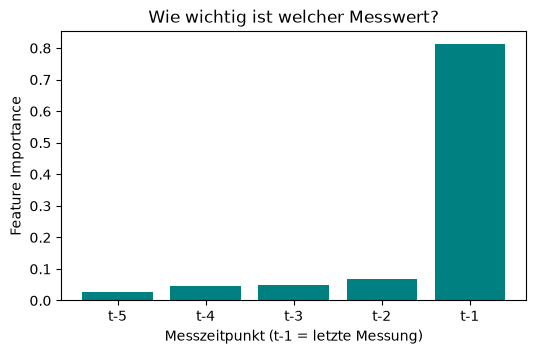

In [19]:
wichtigkeit = pd.Series(finales_modell.feature_importances_, index=sequences.columns)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(wichtigkeit.index, wichtigkeit.values, color="teal")
ax.set_xlabel("Messzeitpunkt (t-1 = letzte Messung)")
ax.set_ylabel("Feature Importance")
ax.set_title("Wie wichtig ist welcher Messwert?")
plt.show()

Die **letzte Messung** dominiert: Sie trägt rund vier Fünftel bei, die älteren Werte nur wenig. Das ist klinisch plausibel, denn der aktuelle Zustand ist der beste Prädiktor für den nächsten. Es erklärt auch, warum längere Sequenzen in 2.4 kaum etwas gebracht haben.

## 2.7 Ein Verlauf im Detail

Wie sieht das in einem echten Verlauf aus? Wir nehmen den Test-Aufenthalt mit den meisten Messungen. Die Zielwerte liegen innerhalb eines Aufenthalts in zeitlicher Reihenfolge vor, weil `create_sequences` die Daten pro Aufenthalt sortiert hat.

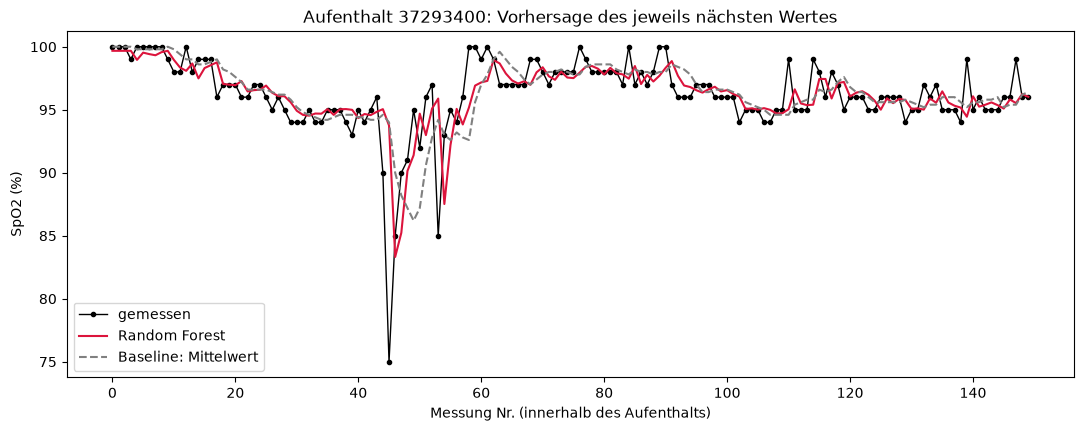

In [20]:
beispiel_stay = pd.Series(stays_te).value_counts().index[0]
maske = stays_te == beispiel_stay
ausschnitt = slice(0, 150)    # die ersten 150 Vorhersagen dieses Aufenthalts

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(y_te[maske][ausschnitt], color="black", marker="o", markersize=3, linewidth=1,
        label="gemessen")
ax.plot(y_pred_final[maske][ausschnitt], color="crimson", label="Random Forest")
ax.plot(y_baseline[maske][ausschnitt], color="gray", linestyle="--", label="Baseline: Mittelwert")
ax.set_xlabel("Messung Nr. (innerhalb des Aufenthalts)")
ax.set_ylabel("SpO2 (%)")
ax.set_title(f"Aufenthalt {beispiel_stay}: Vorhersage des jeweils nächsten Wertes")
ax.legend()
plt.show()

Gut zu sehen: Beide Vorhersagen verlaufen **glatt** und **hinken** den Messwerten hinterher. Kurze Einbrüche werden nicht vorhergesagt, sondern erst nach ihrem Auftreten „eingepreist“. Das Modell beschreibt den aktuellen Zustand gut, sieht aber nicht in die Zukunft.

## 2.8 Klinischer Nutzen: Werden Entsättigungen erkannt?

Für ein Frühwarnsystem zählt nicht der mittlere Fehler, sondern: *Wird eine Entsättigung rechtzeitig erkannt?* Dazu betrachten wir zuerst den Fehler getrennt nach $SpO_2$-Bereichen:

In [21]:
bereiche = pd.cut(y_te, bins=[0, 90, 95, 101], right=False,
                  labels=["< 90 %", "90–94 %", "≥ 95 %"])

pd.DataFrame({
    "Anzahl": pd.Series(y_te).groupby(bereiche, observed=True).size(),
    "MAE Random Forest": pd.Series(np.abs(y_pred_final - y_te)).groupby(bereiche, observed=True).mean(),
    "MAE Baseline": pd.Series(np.abs(y_baseline - y_te)).groupby(bereiche, observed=True).mean(),
}).round(2)

,Anzahl,MAE Random Forest,MAE Baseline
< 90 %,39,6.98,6.29
90–94 %,526,2.02,1.95
≥ 95 %,2173,1.02,1.12


Im kritischen Bereich unter 90 % liegt das Modell im Mittel **um mehrere Prozentpunkte daneben**, bei gleichzeitig sehr wenigen Beispielen. Werte unter 90 % sind selten, das Modell hat kaum gelernt, sie vorherzusagen.

Jetzt die Frage als Klassifikation (Tutorial 04): Wenn wir **„nächster Wert < 92 %“** als Alarm definieren, wie gut erkennt das Modell solche Situationen?

In [22]:
def alarm_guete(y_wahr, y_vorhersage, grenze=92, alarmgrenze=None):
    # grenze:      ab wann gilt der wahre Wert als Entsättigung
    # alarmgrenze: ab welchem vorhergesagten Wert Alarm gegeben wird (Standard: = grenze)
    if alarmgrenze is None:
        alarmgrenze = grenze
    wahr = y_wahr < grenze
    alarm = y_vorhersage < alarmgrenze
    tp = (wahr & alarm).sum()
    fn = (wahr & ~alarm).sum()
    fp = (~wahr & alarm).sum()
    return {
        "Entsättigungen": int(wahr.sum()),
        "erkannt": int(tp),
        "Sensitivität": tp / (tp + fn),
        "Alarme": int(tp + fp),
        "PPV": tp / (tp + fp) if (tp + fp) > 0 else np.nan,
    }

pd.DataFrame({
    "Random Forest": alarm_guete(y_te, y_pred_final),
    "Baseline: Mittelwert": alarm_guete(y_te, y_baseline),
    "Baseline: letzter Wert": alarm_guete(y_te, X_te["t-1"].values),
}).T.round(2)

,Entsättigungen,erkannt,Sensitivität,Alarme,PPV
Random Forest,103.0,18.0,0.17,39.0,0.46
Baseline: Mittelwert,103.0,35.0,0.34,86.0,0.41
Baseline: letzter Wert,103.0,38.0,0.37,103.0,0.37


Ein großer Teil der Entsättigungen wird von **allen** Verfahren übersehen. Und noch etwas fällt auf: Ausgerechnet der Random Forest, der beim MAE am besten abschneidet, erkennt die **wenigsten** Entsättigungen.

Das ist kein Widerspruch. Das Modell wurde darauf optimiert, *im Mittel* möglichst wenig danebenzuliegen. Da 96 % der Werte ≥ 92 % sind, lohnt es sich für das Modell, vorsichtig „normale“ Werte vorherzusagen. Seltene Ereignisse werden dabei weggeglättet. **Ein besseres Gütemaß bedeutet nicht automatisch einen besseren klinischen Nutzen.**

### Die Alarmgrenze verschieben
Man kann die Sensitivität erhöhen, indem man schon bei einer höheren Vorhersage Alarm gibt. Was passiert dabei mit der Zahl der Alarme?

In [23]:
zeilen = {}
for alarmgrenze in [92, 93, 94, 95, 96]:
    zeilen[f"Alarm bei Vorhersage < {alarmgrenze} %"] = alarm_guete(
        y_te, y_pred_final, grenze=92, alarmgrenze=alarmgrenze)
pd.DataFrame(zeilen).T.round(2)

,Entsättigungen,erkannt,Sensitivität,Alarme,PPV
Alarm bei Vorhersage < 92 %,103.0,18.0,0.17,39.0,0.46
Alarm bei Vorhersage < 93 %,103.0,35.0,0.34,99.0,0.35
Alarm bei Vorhersage < 94 %,103.0,54.0,0.52,194.0,0.28
Alarm bei Vorhersage < 95 %,103.0,73.0,0.71,566.0,0.13
Alarm bei Vorhersage < 96 %,103.0,90.0,0.87,1168.0,0.08


Mit höherer Alarmgrenze werden mehr Entsättigungen erkannt, aber die Zahl der Alarme steigt stark, und ein immer größerer Teil davon sind Fehlalarme (der PPV sinkt). Auf Intensivstationen ist **Alarm Fatigue**, die Abstumpfung des Personals durch zu viele Fehlalarme, ein ernstes Patientensicherheitsproblem. Die Wahl der Grenze ist, wie in Tutorial 04, eine **klinische** Entscheidung.

---
# Teil 3: Evaluation und Interpretation des finalen Modells

In Teil 2 haben wir das finale Modell gefunden: einen Random Forest mit `min_samples_leaf=20`, getestet an 20 Patient\*innen, die das Modell nie gesehen hat. Jetzt schauen wir es uns systematisch an, in zwei Schritten:

- **Evaluation** – *Wie gut* ist das Modell? Wie stabil ist das Ergebnis? Für wen funktioniert es, für wen nicht?
- **Interpretation** – *Was* hat das Modell eigentlich gelernt? Welche Regeln wendet es an, und sind sie klinisch plausibel?

## 3.1 Evaluation: Wie stabil ist das Ergebnis? (Kreuzvalidierung)

Ein MAE von 1,30 gegenüber 1,36 bei der Baseline: Ist dieser Unterschied verlässlich oder hatten wir bei der Auswahl der 20 Test-Patient\*innen einfach Glück? Ein einzelner Train-Test-Split kann das nicht beantworten.

Die Standardmethode dafür ist die **k-fache Kreuzvalidierung** (Tutorial 04, Abschnitt 10). Wir teilen die Patient\*innen in 10 Gruppen (*Folds*) auf. Dann trainieren wir das Modell 10-mal, jedes Mal auf 9 Gruppen, und testen auf der übrig gebliebenen. So wird **jede Person genau einmal** zur Test-Person, und wir erhalten 10 Ergebnisse statt einem.

**Wichtig:**
- Wir verwenden `GroupKFold` mit der `subject_id`, damit alle Daten einer Person im selben Fold landen (siehe 2.2).
- Die Baseline wird auf **denselben** Folds berechnet. Nur so ist der Vergleich fair: Modell und Baseline werden pro Fold an genau denselben Personen gemessen (*gepaarter Vergleich*).

Da wir zwei Verfahren auf denselben Folds vergleichen wollen, schreiben wir die Schleife selbst, statt `cross_val_score` zu verwenden. *(Diese Zelle rechnet etwa eine halbe Minute.)*

In [24]:
cv_ergebnisse = []

for fold, (train_f, test_f) in enumerate(GroupKFold(n_splits=10).split(sequences, targets, groups=subject_ids), start=1):
    modell_f = RandomForestRegressor(min_samples_leaf=20, random_state=42, n_jobs=-1)
    modell_f.fit(sequences.iloc[train_f], targets[train_f])

    y_wahr_f = targets[test_f]
    mae_rf = mean_absolute_error(y_wahr_f, modell_f.predict(sequences.iloc[test_f]))
    mae_bl = mean_absolute_error(y_wahr_f, sequences.iloc[test_f].mean(axis=1))

    cv_ergebnisse.append({
        "Fold": fold,
        "Test-Patient*innen": len(np.unique(subject_ids[test_f])),
        "MAE Random Forest": mae_rf,
        "MAE Baseline": mae_bl,
        "Verbesserung": mae_bl - mae_rf,
    })

cv_df = pd.DataFrame(cv_ergebnisse).set_index("Fold")
cv_df.round(3)

,Test-Patient*innen,MAE Random Forest,MAE Baseline,Verbesserung
Fold,,,,
1,10,1.331,1.370,0.038
2,10,1.429,1.487,0.058
3,9,1.422,1.421,-0.001
4,9,1.340,1.355,0.016
5,11,1.429,1.465,0.036
6,11,1.295,1.335,0.041
7,10,1.202,1.306,0.103
8,10,1.335,1.376,0.040
9,10,1.371,1.473,0.102


In [25]:
zusammenfassung = cv_df[["MAE Random Forest", "MAE Baseline", "Verbesserung"]].agg(["mean", "std", "min", "max"])
zusammenfassung.index = ["Mittelwert", "SD", "Minimum", "Maximum"]
print(f"Random Forest besser in {(cv_df['Verbesserung'] > 0).sum()} von {len(cv_df)} Folds")
zusammenfassung.round(3)

Random Forest besser in 9 von 10 Folds


,MAE Random Forest,MAE Baseline,Verbesserung
Mittelwert,1.348,1.399,0.051
SD,0.070,0.062,0.034
Minimum,1.202,1.306,-0.001
Maximum,1.429,1.487,0.103


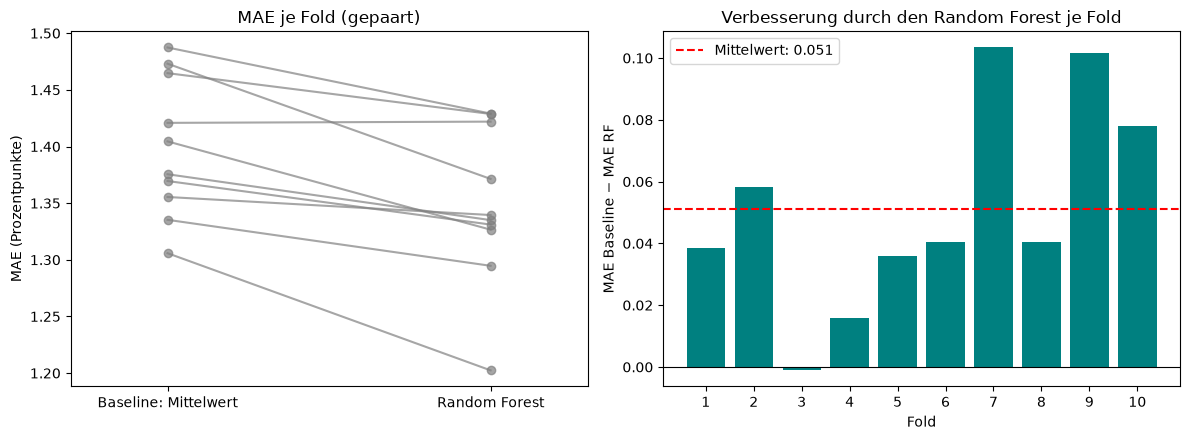

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Links: gepaarter Vergleich, eine Linie pro Fold
for _, zeile in cv_df.iterrows():
    ax1.plot([0, 1], [zeile["MAE Baseline"], zeile["MAE Random Forest"]],
             color="gray", marker="o", alpha=0.7)
ax1.set_xticks([0, 1])
ax1.set_xticklabels(["Baseline: Mittelwert", "Random Forest"])
ax1.set_xlim(-0.3, 1.3)
ax1.set_ylabel("MAE (Prozentpunkte)")
ax1.set_title("MAE je Fold (gepaart)")

# Rechts: Verbesserung je Fold
ax2.bar(cv_df.index.astype(str), cv_df["Verbesserung"], color="teal")
ax2.axhline(0, color="black", linewidth=0.8)
ax2.axhline(cv_df["Verbesserung"].mean(), color="red", linestyle="--",
            label=f"Mittelwert: {cv_df['Verbesserung'].mean():.3f}")
ax2.set_xlabel("Fold")
ax2.set_ylabel("MAE Baseline − MAE RF")
ax2.set_title("Verbesserung durch den Random Forest je Fold")
ax2.legend()

fig.tight_layout()
plt.show()

**Interpretation:**
- Der MAE des Random Forest liegt über die 10 Folds bei etwa **1,35 ± 0,07** Prozentpunkten (Mittelwert ± SD). Das Ergebnis aus dem einzelnen Split (1,30) lag also eher am günstigen Ende.
- Die Schwankung **zwischen den Folds** (etwa 1,2 bis 1,43) ist größer als der Unterschied zwischen Modell und Baseline. Welche Patient\*innen im Test landen, beeinflusst das Ergebnis also stärker als die Wahl des Verfahrens.
- Im gepaarten Vergleich ist der Random Forest aber in **9 von 10 Folds** besser, im Mittel um rund **0,05 Prozentpunkte**. Der Vorsprung ist also konsistent, nur eben sehr klein. Konsistent nachweisbar heißt nicht klinisch relevant – ein bekanntes Prinzip aus der Studienbewertung.

> **Einschränkungen:**
> - Die 10 Fold-Ergebnisse sind **nicht unabhängig**, weil sich die Trainingsdaten der Folds zu großen Teilen überschneiden. Ein klassischer t-Test über die Folds wäre deshalb zu optimistisch. Mittelwert und SD sind als Beschreibung der Stabilität gedacht, nicht als Signifikanztest.
> - Die Blattgröße wurde in 2.3 auf denselben Daten ausgewählt. Wer ganz sauber vorgehen will, verwendet eine **verschachtelte Kreuzvalidierung** (*nested cross-validation*): eine innere Kreuzvalidierung zur Auswahl der Hyperparameter innerhalb jedes äußeren Folds.

## 3.2 Evaluation: Bland-Altman-Plot

Wie vergleicht man in der Medizin zwei Messmethoden, z. B. ein neues Blutdruckgerät mit dem Goldstandard? Mit dem **Bland-Altman-Plot**. Wir können unser Modell genauso behandeln: als „Messmethode“, die den nächsten $SpO_2$-Wert schätzt.

- x-Achse: Mittelwert aus Vorhersage und wahrem Wert
- y-Achse: Differenz Vorhersage − wahrer Wert
- **Bias** (mittlere Differenz): Liegt das Modell systematisch zu hoch oder zu tief?
- **Limits of Agreement** (Bias ± 1,96 × SD): In diesem Bereich liegen etwa 95 % aller Abweichungen.

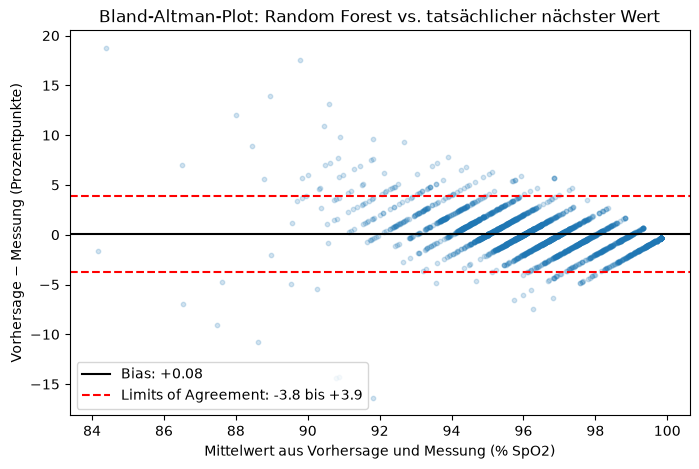

In [ ]:
differenz = y_pred_final - y_te
mittel = (y_pred_final + y_te) / 2
bias = differenz.mean()
sd = differenz.std(ddof=1)
loa_unten, loa_oben = bias - 1.96 * sd, bias + 1.96 * sd

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(mittel, differenz, alpha=0.2, s=10)
ax.axhline(bias, color="black", label=f"Bias: {bias:+.2f}")
ax.axhline(loa_unten, color="red", linestyle="--", label=f"Limits of Agreement: {loa_unten:.1f} bis {loa_oben:+.1f}")
ax.axhline(loa_oben, color="red", linestyle="--")
ax.set_xlabel("Mittelwert aus Vorhersage und Messung (% $SpO_2$)")
ax.set_ylabel("Vorhersage − Messung (Prozentpunkte)")
ax.set_title("Bland-Altman-Plot: Random Forest vs. tatsächlicher nächster Wert")
ax.legend(loc="lower left")
plt.show()

**Interpretation:**
- Der **Bias** ist praktisch 0: Über alle Werte hinweg liegt das Modell weder systematisch zu hoch noch zu tief.
- Die **Limits of Agreement** liegen bei etwa ±4 Prozentpunkten: 95 % der Vorhersagen weichen höchstens so weit vom tatsächlich gemessenen nächsten Wert ab.
- Zur Einordnung: Pulsoxymeter dürfen für die Zulassung eine mittlere quadratische Abweichung (*A<sub>rms</sub>*) von bis zu etwa 3 Prozentpunkten gegenüber der arteriellen Blutgasanalyse haben. Der RMSE unseres Modells (≈ 2) liegt in derselben Größenordnung. Die Fehler des Modells sind also kaum größer als die Messungenauigkeit des Geräts selbst. Genauer kann man einen verrauschten Messwert kaum vorhersagen.
- Die schrägen Streifen sind kein Fehler: Sie entstehen, weil die Messwerte ganzzahlig sind.
- Aber: Im linken Bereich (niedrige Werte) liegen fast alle Punkte **oberhalb** von 0. Im Gesamt-Bias geht das unter, weil dort so wenige Werte liegen. Bei Entsättigungen überschätzt das Modell den $SpO_2$ **systematisch**, und das ist die gefährliche Richtung.

## 3.3 Evaluation: Für wen funktioniert das Modell?

Ein Durchschnittswert über alle Test-Patient\*innen kann verdecken, dass das Modell bei einzelnen Personen deutlich schlechter ist. Wir berechnen den MAE deshalb **pro Person**:

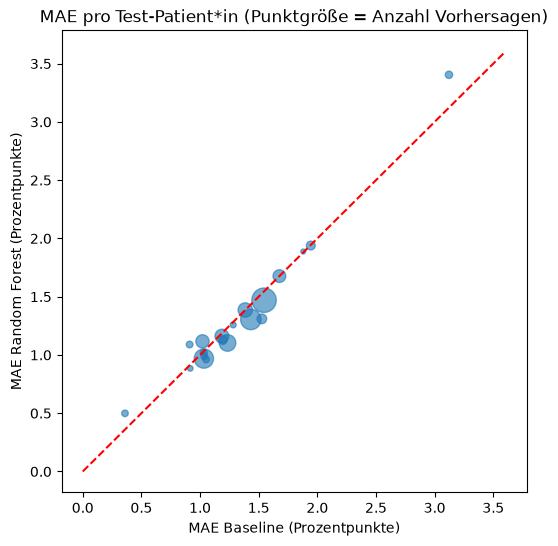

Random Forest besser bei 13 von 20 Patient*innen


,n,mae_rf,mae_baseline
subject_id,,,
10026255,36,3.40,3.12
10007928,61,1.94,1.94
10000032,5,1.89,1.88
10002495,149,1.68,1.68
10023117,600,1.47,1.55


In [28]:
fehler_df = pd.DataFrame({
    "subject_id": subject_ids[test_idx],
    "rf":         np.abs(y_pred_final - y_te),
    "baseline":   np.abs(y_baseline - y_te),
})
mae_pro_person = fehler_df.groupby("subject_id").agg(
    n=("rf", "size"), mae_rf=("rf", "mean"), mae_baseline=("baseline", "mean"))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(mae_pro_person["mae_baseline"], mae_pro_person["mae_rf"],
           s=mae_pro_person["n"] / 2 + 10, alpha=0.6)
grenze = mae_pro_person[["mae_rf", "mae_baseline"]].max().max() + 0.2
ax.plot([0, grenze], [0, grenze], color="red", linestyle="--")
ax.set_xlabel("MAE Baseline (Prozentpunkte)")
ax.set_ylabel("MAE Random Forest (Prozentpunkte)")
ax.set_title("MAE pro Test-Patient*in (Punktgröße = Anzahl Vorhersagen)")
plt.show()

besser = (mae_pro_person["mae_rf"] < mae_pro_person["mae_baseline"]).sum()
print(f"Random Forest besser bei {besser} von {len(mae_pro_person)} Patient*innen")
mae_pro_person.sort_values("mae_rf", ascending=False).head(5).round(2)

**Interpretation:**
- Punkte **unterhalb** der Diagonale: Dort ist der Random Forest besser. Das ist bei gut der Hälfte der Patient\*innen der Fall, aber nicht bei allen.
- Der MAE schwankt zwischen den Personen um ein Vielfaches (etwa 0,5 bis über 3 Prozentpunkte). Bei Patient\*innen mit instabilem Verlauf ist das Modell deutlich schlechter. Genau diese Patient\*innen wären aber für ein Frühwarnsystem interessant.
- Die Patient\*innen mit vielen Messungen (große Punkte) bestimmen den Gesamt-MAE am stärksten. Eine Person mit 600 Messungen zählt so viel wie 20 Personen mit 30 Messungen.

## 3.4 Evaluation: Welche Rolle spielt der Zeitabstand?

Unser Modell kennt nur die Reihenfolge der Messungen, nicht ihren zeitlichen Abstand. Ob die nächste Messung 10 Minuten oder 5 Stunden später erfolgt, weiß es nicht. Wir berechnen deshalb zu jeder Sequenz den Abstand zwischen der letzten Eingabemessung und dem Zielwert. Die Funktion durchläuft die Daten in **genau derselben Reihenfolge** wie `create_sequences`, damit die Werte zusammenpassen.

In [29]:
def zeitabstaende(data, sequence_length=5):
    abstaende = []
    for stay_id in data["stay_id"].unique():
        zeiten = data[data["stay_id"] == stay_id].sort_values("time")["time"]
        minuten = zeiten.diff().dt.total_seconds() / 60    # Abstand zur jeweils vorherigen Messung
        abstaende.extend(minuten.iloc[sequence_length:].tolist())
    return np.array(abstaende)

abstand = zeitabstaende(data)
assert len(abstand) == len(targets)     # Kontrolle: passt zu den Sequenzen
abstand_te = abstand[test_idx]

abstand_gruppe = pd.cut(abstand_te, bins=[0, 30, 61, 121, np.inf], right=False,
                        labels=["< 30 min", "30–60 min", "61–120 min", "> 2 h"])
pd.DataFrame({
    "Anzahl": pd.Series(abstand_te).groupby(abstand_gruppe, observed=True).size(),
    "MAE Random Forest": pd.Series(np.abs(y_pred_final - y_te)).groupby(abstand_gruppe, observed=True).mean(),
}).round(2)

,Anzahl,MAE Random Forest
< 30 min,424,1.37
30–60 min,2146,1.24
61–120 min,143,1.82
> 2 h,25,2.32


**Interpretation:** Die meisten Messungen erfolgen stündlich. Liegt mehr als eine Stunde bis zur nächsten Messung, steigt der Fehler deutlich. Das ist plausibel: In zwei Stunden kann sich mehr verändern als in einer. Hier liegt ein konkreter Ansatzpunkt für eine Verbesserung: Man könnte den Zeitabstand als **zusätzliches Merkmal** ins Modell aufnehmen.

## 3.5 Interpretation: Permutation Importance

In 2.6 haben wir die eingebaute Feature Importance des Random Forest angesehen. Sie hat einen Haken: Sie wird auf den **Trainingsdaten** berechnet und kann dadurch verzerrt sein. Ein robusteres Verfahren ist die **Permutation Importance** auf den Testdaten:

> Man mischt die Werte einer Spalte zufällig durcheinander und misst, um wie viel das Modell schlechter wird. Braucht das Modell die Spalte, steigt der Fehler stark. Ist sie egal, ändert sich nichts.

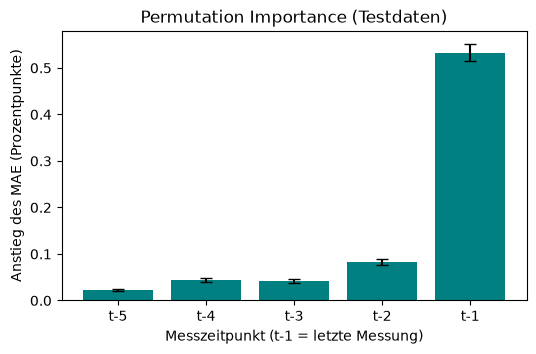

,Anstieg MAE bei Permutation,SD
t-5,0.023,0.002
t-4,0.044,0.004
t-3,0.042,0.005
t-2,0.083,0.006
t-1,0.533,0.019


In [30]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(finales_modell, X_te, y_te, n_repeats=10, random_state=42,
                              scoring="neg_mean_absolute_error", n_jobs=-1)

perm_df = pd.DataFrame({
    "Anstieg MAE bei Permutation": perm.importances_mean,
    "SD": perm.importances_std,
}, index=X_te.columns)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(perm_df.index, perm_df["Anstieg MAE bei Permutation"],
       yerr=perm_df["SD"], color="teal", capsize=4)
ax.set_xlabel("Messzeitpunkt (t-1 = letzte Messung)")
ax.set_ylabel("Anstieg des MAE (Prozentpunkte)")
ax.set_title("Permutation Importance (Testdaten)")
plt.show()
perm_df.round(3)

**Interpretation:** Das Bild bestätigt 2.6. Wird die letzte Messung durcheinandergemischt, steigt der MAE um rund einen halben Prozentpunkt, also um etwa 40 %. Alle älteren Messungen zusammen sind deutlich weniger wichtig. Die vorletzte Messung (`t-2`) hat dabei noch den größten Einfluss. Das Modell nutzt die Vorgeschichte, um einzuschätzen, ob der letzte Wert „echt“ oder ein Ausreißer ist.

## 3.6 Interpretation: Wie hängt die Vorhersage vom letzten Wert ab?

Die Importance sagt nur, *wie stark* ein Merkmal genutzt wird, nicht *wie*. Das zeigt ein **Partial-Dependence-Plot**: Man setzt für alle Testfälle `t-1` nacheinander auf verschiedene Werte und schaut, wie sich die mittlere Vorhersage verändert.

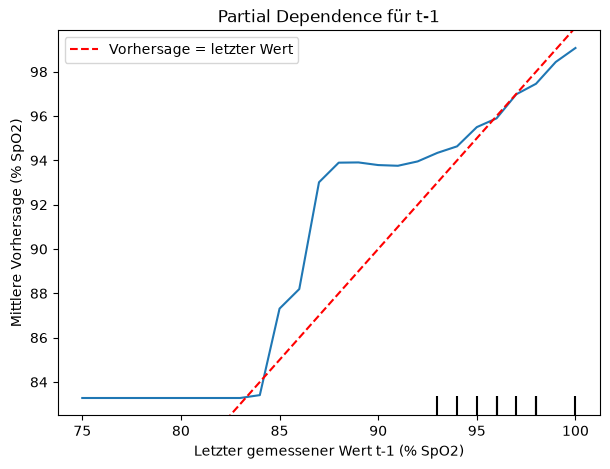

In [31]:
from sklearn.inspection import PartialDependenceDisplay

fig, ax = plt.subplots(figsize=(7, 5))
anzeige = PartialDependenceDisplay.from_estimator(
    finales_modell, X_te, features=["t-1"], grid_resolution=40, ax=ax)
achse = anzeige.axes_[0][0]
achse.plot([75, 100], [75, 100], color="red", linestyle="--", label="Vorhersage = letzter Wert")
achse.set_xlabel("Letzter gemessener Wert t-1 (% SpO2)")
achse.set_ylabel("Mittlere Vorhersage (% SpO2)")
achse.set_title("Partial Dependence für t-1")
achse.legend()
plt.show()

**Interpretation:**
- Im Normalbereich (ca. 93–100 %) folgt die Vorhersage dem letzten Wert, aber **flacher als die Diagonale**: Ein hoher Wert wird etwas nach unten, ein niedriger etwas nach oben korrigiert. Das ist die **Regression zur Mitte**. Ein auffälliger Einzelwert ist oft teilweise Messrauschen, deshalb ist der nächste Wert im Mittel wieder näher am Durchschnitt.
- Die Kurve ist **stufig**, nicht glatt. So arbeiten Entscheidungsbäume: Sie teilen den Wertebereich in Abschnitte und sagen pro Abschnitt einen Mittelwert vorher.
- Unterhalb von etwa 93 % liegt die Kurve deutlich **über** der Diagonale: Das Modell „glaubt“ einem niedrigen letzten Wert nur teilweise, vor allem wenn die Werte davor normal waren.
- Unterhalb von etwa 83 % wird die Kurve **flach**. Ob der letzte Wert 75 % oder 83 % war, ändert die Vorhersage nicht. Dort gab es zu wenige Trainingsdaten. Ein Random Forest kann **nicht extrapolieren**, also nichts vorhersagen, was außerhalb dessen liegt, was er häufig genug gesehen hat.
- Zwischen 83 und 93 % verläuft die Kurve sprunghaft: Ein letzter Wert von 85 % wird weitgehend übernommen, einer von 89 % dagegen fast auf 94 % „hochkorrigiert“. Das hat keine physiologische Logik, sondern beruht auf den wenigen Trainingsfällen in diesem Bereich. **Nicht jedes gelernte Muster ist klinisch sinnvoll interpretierbar.**

## 3.7 Interpretation: Was-wäre-wenn-Szenarien

Die anschaulichste Art, ein Modell zu verstehen: Man legt ihm **typische klinische Verläufe** vor und schaut, was es antwortet. Sozusagen eine „Fallbesprechung“ mit dem Modell.

In [32]:
szenarien = pd.DataFrame(
    [[97, 97, 97, 97, 97],
     [98, 96, 94, 92, 90],
     [97, 97, 97, 97, 85],
     [85, 88, 91, 94, 96],
     [88, 88, 88, 88, 88],
     [100, 100, 100, 100, 100]],
    columns=X_te.columns,
    index=["stabil normal", "kontinuierlicher Abfall", "einzelner Ausreißer nach unten",
           "Erholung nach Entsättigung", "stabil niedrig", "stabil 100 %"],
)
ergebnis = szenarien.copy()
ergebnis["Random Forest"] = finales_modell.predict(szenarien).round(1)
ergebnis["Baseline: Mittelwert"] = szenarien.mean(axis=1).round(1)
ergebnis

,t-5,t-4,t-3,t-2,t-1,Random Forest,Baseline: Mittelwert
stabil normal,97,97,97,97,97,97.0,97.0
kontinuierlicher Abfall,98,96,94,92,90,94.2,94.0
einzelner Ausreißer nach unten,97,97,97,97,85,87.8,94.6
Erholung nach Entsättigung,85,88,91,94,96,94.6,90.8
stabil niedrig,88,88,88,88,88,91.4,88.0
stabil 100 %,100,100,100,100,100,99.7,100.0


**Interpretation, Fall für Fall:**

| Szenario | Was das Modell tut | Klinische Bewertung |
|---|---|---|
| stabil normal | sagt den gleichen Wert voraus | ✅ sinnvoll |
| **kontinuierlicher Abfall** | sagt ca. 94 % voraus, also **höher** als der letzte Wert (90 %) | ⚠️ Der Trend wird nicht fortgeschrieben, sondern „zurückgeholt“. Eine Ärztin würde hier mit weiterem Abfall rechnen. |
| einzelner Ausreißer nach unten | folgt dem letzten Wert weitgehend (ca. 88 %) | ⚖️ vorsichtig, aber ein Sensorartefakt würde als echt gewertet. Die Baseline (Mittelwert) glättet hier stärker. |
| Erholung | sagt etwas weniger als den letzten Wert voraus | ✅ plausibel |
| stabil niedrig (88 %) | zieht die Vorhersage nach oben (ca. 91 %) | ⚠️ Regression zur Mitte: Das Modell „glaubt“ niedrige Werte nicht ganz. |
| stabil 100 % | knapp unter 100 % | ✅ nie über 100 %, physiologisch möglich |

**Gesamtbild:** Das Modell hat im Wesentlichen eine **Glättungsregel** gelernt: „Nimm vor allem den letzten Wert und ziehe ihn etwas Richtung Normalbereich.“ **Trends** erkennt es nicht. Für ein Frühwarnsystem wäre aber genau das entscheidend. Der Grund: In den Trainingsdaten folgt auf einen Abfall meist wieder eine Erholung (Messartefakte, Umlagerung, erhöhte Sauerstoffgabe). Das Modell hat also aus den Daten korrekt gelernt, dass Abfälle oft nicht anhalten. Die Behandlung, die den Abfall beendet hat, ist für das Modell aber unsichtbar.

> **Für die Diskussion:** Dieses Problem heißt in der Literatur auch *treatment paradox*: Weil Patient\*innen mit kritischen Werten behandelt werden, „lernt“ ein Modell, dass kritische Werte harmlos sind.

## 3.8 Zusammenfassung: Steckbrief des Modells

In der Forschung fasst man Modelle zunehmend in einem kurzen **Steckbrief** zusammen (*Model Card*). Für unser Modell könnte das so aussehen:

| | |
|---|---|
| **Aufgabe** | Vorhersage des nächsten $SpO_2$-Messwerts aus den letzten 5 Messungen |
| **Daten** | 100 Patient\*innen, 140 Intensivaufenthalte, ca. 12.800 Sequenzen; eine Klinik (USA) |
| **Modell** | Random Forest Regressor, 100 Bäume, `min_samples_leaf=20` |
| **Validierung** | Aufteilung nach Patient\*innen (80:20) sowie 10-fache Kreuzvalidierung nach Patient\*innen; keine externe Validierung |
| **Güte** | MAE 1,35 ± 0,07 Prozentpunkte (10-fache Kreuzvalidierung), Bias ≈ 0, Limits of Agreement ≈ ±4 Prozentpunkte |
| **Vergleich** | geringfügig besser als „Mittelwert der letzten 5 Werte“ (≈ 0,05 Prozentpunkte, in 9 von 10 Folds) |
| **Stärken** | stabil im Normalbereich, keine unmöglichen Werte, schnell, nachvollziehbar |
| **Schwächen** | erkennt Trends und Entsättigungen schlecht (Sensitivität für < 92 % ca. 17 %), überschätzt niedrige Werte systematisch, ignoriert Zeitabstände |
| **Einsatz** | ❌ nicht für klinische Entscheidungen geeignet; nur Lehrbeispiel |

---
# Fazit und Diskussion

### Was wir gelernt haben
1. **Ein Gütemaß ohne Vergleich ist wertlos.** Ein MAE von 1,5 % klingt gut, ist aber nicht besser als „Mittelwert der letzten 5 Werte“.
2. **Standardeinstellungen sind nicht immer gut.** Bei verrauschten Daten überfittet ein Random Forest mit voll ausgewachsenen Bäumen. Mit `min_samples_leaf` schlägt er die Baseline, aber nur knapp.
3. **Ehrlich testen:** Aufteilung nach Patient\*innen, nicht nach Zeilen.
4. **Mittlere Fehler verstecken klinisch relevante Fehler.** Im kritischen Bereich ist das Modell am schlechtesten, und das Modell mit dem besten MAE erkennt die wenigsten Entsättigungen.
5. **Konsistent ist nicht klinisch relevant.** Der Vorsprung vor der Baseline zeigt sich in fast allen Folds der Kreuzvalidierung, ist aber winzig.
6. **Interpretieren lohnt sich.** Das Modell hat eine Glättungsregel mit Regression zur Mitte gelernt und erkennt keine Trends. Das sieht man an keiner einzelnen Kennzahl, aber sofort an den Szenarien.

### Macht der Random Forest hier also Sinn?
**Als Methode ja**: Er ist eine sehr gute erste Wahl für tabellarische Daten, robust, schnell, ohne viel Vorverarbeitung, und er liefert nur physiologisch mögliche Werte. **Als klinisches Werkzeug in dieser Form nein**: Die 5 vorherigen $SpO_2$-Werte enthalten einfach zu wenig Information über die Zukunft. Das liegt nicht am Algorithmus, sondern an den **Daten**. Ein komplexeres Modell würde daran wenig ändern.

### Diskussionsfragen
1. Welche **zusätzlichen Informationen** könnten die Vorhersage verbessern? (z. B. Herzfrequenz, Atemfrequenz, Sauerstoffgabe, Beatmungsparameter, Diagnosen)
2. Die Messungen liegen meist im Abstand von einer Stunde, aber manchmal nur 1 Minute oder über 10 Stunden auseinander. Wie könnte man den **zeitlichen Abstand** ins Modell einbauen?
3. Ist „nächster Wert“ überhaupt das richtige Ziel? Wäre „**Entsättigung in den nächsten 2 Stunden** ja/nein“ klinisch sinnvoller, und welches Modell bräuchte man dafür?
4. Die Daten stammen von 100 Patient\*innen einer US-amerikanischen Klinik. Würden Sie das Modell auf Ihrer Station einsetzen? Was müsste vorher passieren?